In [1]:
!pip install -q --no-cache-dir --force-reinstall --no-deps git+https://github.com/RayenSansa03/aeroguard.git@main

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount("/content/drive")

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aeroguard.autoencodeurs import standardiser, statistiques_features
from aeroguard.diversite import diagnostic_diversite, est_effondre
from aeroguard.donnees_ml import preparer_xy
from aeroguard.gan import DIM_BRUIT, creer_discriminateur, creer_generateur, entrainer_gan, generer

DOSSIER = "/content/drive/MyDrive/aeroguard"
FAMILLE_CIBLE = "fan"
EPOCHS = 1500

vols = pd.read_parquet(f"{DOSSIER}/data/processed/vols_ncmapss.parquet")
X_train, y_train = preparer_xy(vols, "train")
medianes = X_train.median()
famille_train = vols.loc[X_train.index, "famille"].astype(str).to_numpy()
cible = (famille_train == FAMILLE_CIBLE) & (np.asarray(y_train) == 1)
X_cible = X_train[cible].fillna(medianes)
colonnes = list(X_cible.columns)

moyennes, ecarts = statistiques_features(X_cible.to_numpy(dtype="float64"))
ecarts = np.where(np.asarray(ecarts) > 0, ecarts, 1.0)
X_reel = standardiser(X_cible.to_numpy(dtype="float64"), moyennes, ecarts).astype("float32")
print(f"{len(X_reel)} vols usés « {FAMILLE_CIBLE} » × {X_reel.shape[1]} features")

# Point de comparaison : la diversité des vrais vols comparés à eux-mêmes
print("Vrais contre vrais :", {k: round(v, 3) for k, v in diagnostic_diversite(X_reel, X_reel).items()})

Mounted at /content/drive
340 vols usés « fan » × 126 features
Vrais contre vrais : {'rapport_ecarts': 1.0, 'part_features_ecrasees': 0.0, 'couverture_queues': 1.0, 'rapport_ppv': 1.0, 'part_doublons': 0.0}


In [3]:
def experience(nom, dim_bruit=DIM_BRUIT, **reglages):
    """Entraîne un GAN neuf avec ces réglages, génère 340 faux vols et mesure leur diversité."""
    debut = time.perf_counter()
    generateur = creer_generateur(X_reel.shape[1], dim_bruit=dim_bruit)
    discriminateur = creer_discriminateur(X_reel.shape[1])
    historique = entrainer_gan(generateur, discriminateur, X_reel, epochs=EPOCHS, taille_lot=64,
                               dim_bruit=dim_bruit, afficher_tous_les=0, **reglages)
    faux = generer(generateur, len(X_reel), dim_bruit=dim_bruit, graine=0)

    if np.isfinite(faux).all():
        diag = diagnostic_diversite(X_reel, faux)
        effondre = est_effondre(diag)
    else:  # entraînement qui a « explosé » (NaN) : échec certain
        diag = dict.fromkeys(["rapport_ecarts", "part_features_ecrasees", "couverture_queues",
                              "rapport_ppv", "part_doublons"], np.nan)
        effondre = True

    ligne = {"experience": nom, **diag, "effondre": effondre,
             "D_vrais_fin": float(np.mean(historique["proba_vrais"][-100:])),
             "D_faux_fin": float(np.mean(historique["proba_faux"][-100:])),
             "duree_s": round(time.perf_counter() - debut)}
    print(f"{nom:24s} → écarts {diag['rapport_ecarts']:.2f} | queues {diag['couverture_queues']:.2f} | "
          f"ppv {diag['rapport_ppv']:.2f} | effondré : {effondre} ({ligne['duree_s']} s)")
    return ligne, historique, generateur, faux

In [4]:
EXPERIENCES = {
    "A_reference_6.2": {},
    "B_taux_trop_fort": {"taux_apprentissage": 5e-3},
    "C_bruit_1_dimension": {"dim_bruit": 1},
    "D_lissage": {"lissage_etiquettes": 0.1},
    "E_lissage_expert_lent": {"lissage_etiquettes": 0.1, "taux_apprentissage_d": 1e-4},
}

lignes, historiques, generateurs, faux_par_exp = [], {}, {}, {}
for nom, reglages in EXPERIENCES.items():
    ligne, historiques[nom], generateurs[nom], faux_par_exp[nom] = experience(nom, **reglages)
    lignes.append(ligne)

resultats = pd.DataFrame(lignes).set_index("experience")
resultats.to_csv(f"{DOSSIER}/results/63_experiences_gan.csv")
resultats.round(3)

A_reference_6.2          → écarts 0.79 | queues 1.18 | ppv 1.10 | effondré : False (49 s)
B_taux_trop_fort         → écarts 0.82 | queues 1.31 | ppv 0.96 | effondré : False (37 s)
C_bruit_1_dimension      → écarts 0.43 | queues 1.18 | ppv 0.01 | effondré : True (34 s)
D_lissage                → écarts 0.77 | queues 1.15 | ppv 1.00 | effondré : False (36 s)
E_lissage_expert_lent    → écarts 0.86 | queues 1.49 | ppv 0.98 | effondré : False (34 s)


,rapport_ecarts,part_features_ecrasees,couverture_queues,rapport_ppv,part_doublons,effondre,D_vrais_fin,D_faux_fin,duree_s
experience,,,,,,,,,
A_reference_6.2,0.790,0.040,1.179,1.102,0.000,False,0.571,0.418,49
B_taux_trop_fort,0.824,0.032,1.306,0.956,0.000,False,0.599,0.347,37
C_bruit_1_dimension,0.431,0.643,1.175,0.005,0.041,True,0.804,0.166,34
D_lissage,0.771,0.016,1.151,1.005,0.000,False,0.527,0.365,36
E_lissage_expert_lent,0.864,0.008,1.492,0.981,0.000,False,0.475,0.423,34


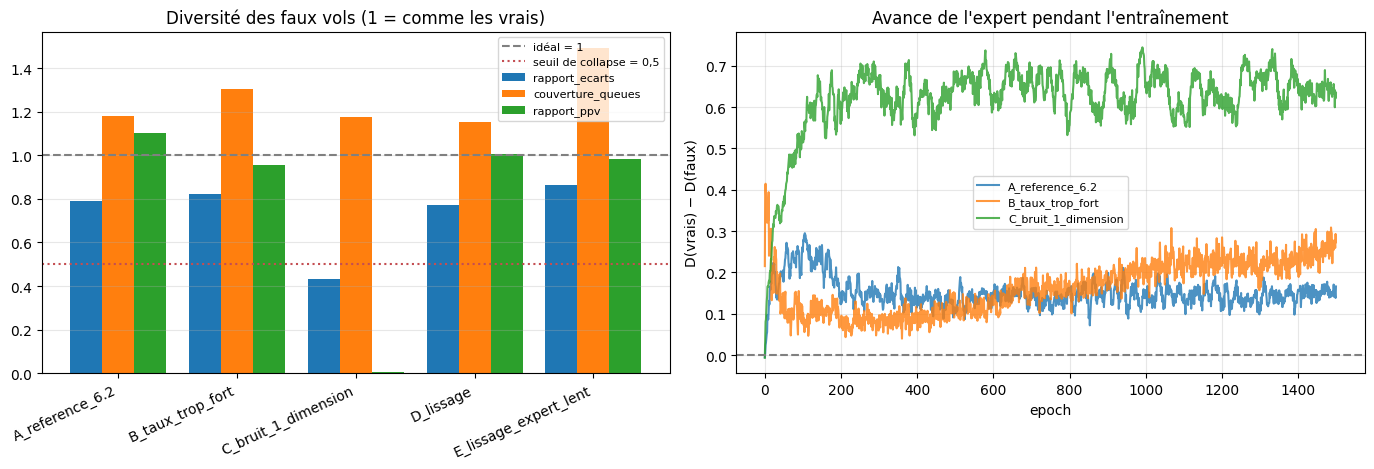

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

mesures = ["rapport_ecarts", "couverture_queues", "rapport_ppv"]
positions = np.arange(len(resultats))
largeur = 0.27
for i, mesure in enumerate(mesures):
    ax1.bar(positions + (i - 1) * largeur, resultats[mesure].fillna(0), largeur, label=mesure)
ax1.axhline(1, color="gray", linestyle="--", label="idéal = 1")
ax1.axhline(0.5, color="#C44E52", linestyle=":", label="seuil de collapse = 0,5")
ax1.set_xticks(positions, resultats.index, rotation=25, ha="right")
ax1.set_title("Diversité des faux vols (1 = comme les vrais)")
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3, axis="y")

for nom in ["A_reference_6.2", "B_taux_trop_fort", "C_bruit_1_dimension"]:
    ecart = np.array(historiques[nom]["proba_vrais"]) - np.array(historiques[nom]["proba_faux"])
    ax2.plot(ecart, label=nom, alpha=0.8)
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_xlabel("epoch")
ax2.set_ylabel("D(vrais) − D(faux)")
ax2.set_title("Avance de l'expert pendant l'entraînement")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/63_mode_collapse.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
candidats = resultats[~resultats["effondre"]].copy()
candidats["score"] = (candidats["couverture_queues"] - 1).abs() + (candidats["rapport_ecarts"] - 1).abs()
candidats = candidats.sort_values("score")
meilleur = candidats.index[0]
print(candidats[["rapport_ecarts", "couverture_queues", "rapport_ppv", "score"]].round(3))
print(f"\n✅ Configuration retenue : {meilleur} → {EXPERIENCES[meilleur] or 'réglages de la 6.2'}")

generateurs[meilleur].save(f"{DOSSIER}/models/gan_fan_v6_stable_generateur.keras")
choix = {"experience": meilleur, "reglages": EXPERIENCES[meilleur], "epochs": EPOCHS,
         "dim_bruit": EXPERIENCES[meilleur].get("dim_bruit", DIM_BRUIT),
         "regle": "min |couverture_queues - 1| + |rapport_ecarts - 1| parmi les non effondrés",
         "diagnostic": {k: round(float(v), 3) for k, v in resultats.loc[meilleur, mesures].items()},
         "stats": "gan_fan_v6_stats.npz (standardisation identique à la 6.2)"}
with open(f"{DOSSIER}/models/gan_fan_v6_stable_config.json", "w") as f:
    json.dump(choix, f, indent=2)
print("Sauvegardé :", choix)

                       rapport_ecarts  couverture_queues  rapport_ppv  score
experience                                                                  
D_lissage                       0.771              1.151        1.005  0.379
A_reference_6.2                 0.790              1.179        1.102  0.389
B_taux_trop_fort                0.824              1.306        0.956  0.482
E_lissage_expert_lent           0.864              1.492        0.981  0.628

✅ Configuration retenue : D_lissage → {'lissage_etiquettes': 0.1}
Sauvegardé : {'experience': 'D_lissage', 'reglages': {'lissage_etiquettes': 0.1}, 'epochs': 1500, 'dim_bruit': 32, 'regle': 'min |couverture_queues - 1| + |rapport_ecarts - 1| parmi les non effondrés', 'diagnostic': {'rapport_ecarts': 0.771, 'couverture_queues': 1.151, 'rapport_ppv': 1.005}, 'stats': 'gan_fan_v6_stats.npz (standardisation identique à la 6.2)'}


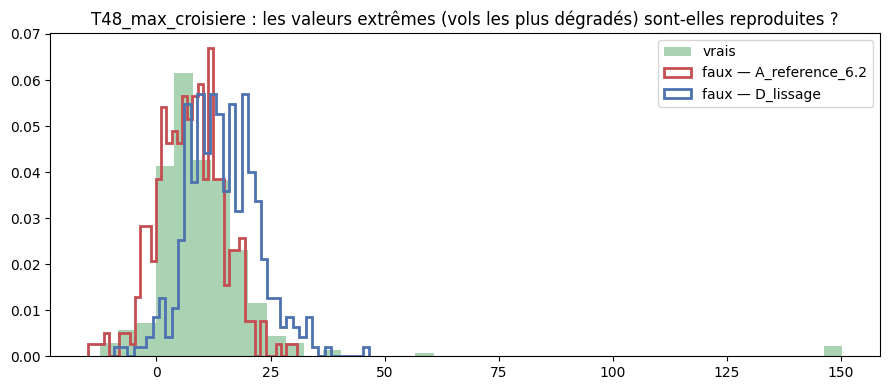

A_reference_6.2          écart-type   7.08 | max  30.76   (vrais : écart-type 15.47, max 150.30)
D_lissage                écart-type   7.75 | max  46.64   (vrais : écart-type 15.47, max 150.30)


In [7]:
colonne = "T48_max_croisiere" if "T48_max_croisiere" in colonnes else colonnes[0]
j = colonnes.index(colonne)
vrais_reels = X_cible[colonne].to_numpy()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(vrais_reels, bins=40, density=True, alpha=0.5, label="vrais", color="#55A868")
for nom, couleur in [("A_reference_6.2", "#C44E52"), (meilleur, "#4C72B0")]:
    valeurs = faux_par_exp[nom][:, j] * ecarts[j] + moyennes[j]
    ax.hist(valeurs, bins=40, density=True, histtype="step", linewidth=2, label=f"faux — {nom}", color=couleur)
ax.set_title(f"{colonne} : les valeurs extrêmes (vols les plus dégradés) sont-elles reproduites ?")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/63_extremes_T48.png", dpi=150, bbox_inches="tight")
plt.show()

for nom in ["A_reference_6.2", meilleur]:
    valeurs = faux_par_exp[nom][:, j] * ecarts[j] + moyennes[j]
    print(f"{nom:24s} écart-type {valeurs.std():6.2f} | max {valeurs.max():6.2f}   "
          f"(vrais : écart-type {vrais_reels.std():.2f}, max {vrais_reels.max():.2f})")